In [3]:
import pandas as pd
df = pd.read_excel('ensaladilla.xls')

# 1. Clean 'Cantidad'
# If it's loaded as a string like "2,00", we convert it to float
if df['Cantidad'].dtype == 'object':
    df['Cantidad'] = df['Cantidad'].str.replace(',', '.').astype(float)

# 2. Process Dates
df['Fecha proceso'] = pd.to_datetime(df['Fecha proceso'], dayfirst=True)

# 3. Create helper columns for grouping
df['Fecha'] = df['Fecha proceso'].dt.date
df['Hora_Slot'] = df['Fecha proceso'].dt.hour  # Extracts just the hour (0-23)

# 4. Aggregate
# We group by Tipo, Date, and the specific Hour, then sum the Cantidad
df_aggregated_hour = df.groupby(['Tipo', 'Fecha', 'Hora_Slot'], as_index=False)['Cantidad'].sum()

# Sort the results for better readability
df_aggregated_hour = df_aggregated_hour.sort_values(by=['Fecha', 'Hora_Slot'])
df_aggregated_day = df_aggregated_hour.groupby(['Tipo', 'Fecha'], as_index=False)['Cantidad'].sum().sort_values(by=['Fecha'])

print(df_aggregated_hour.head())
print(df_aggregated_day.head())

# Optional: Save to a new file
# df_aggregated.to_excel('aggregated_output.xlsx', index=False)

               Tipo       Fecha  Hora_Slot  Cantidad
98   Salida Almacén  2025-01-02         16       9.0
99   Salida Almacén  2025-01-02         19       7.0
100  Salida Almacén  2025-01-02         20       4.0
101  Salida Almacén  2025-01-02         21       2.0
102  Salida Almacén  2025-01-03         17       1.0
                Tipo       Fecha  Cantidad
81    Salida Almacén  2025-01-02      22.0
82    Salida Almacén  2025-01-03       1.0
83    Salida Almacén  2025-01-07      27.0
0   Colocación Carro  2025-01-08     108.0
84    Salida Almacén  2025-01-08      41.0


# Plot aggregated by Hours
Honestly a bit useless

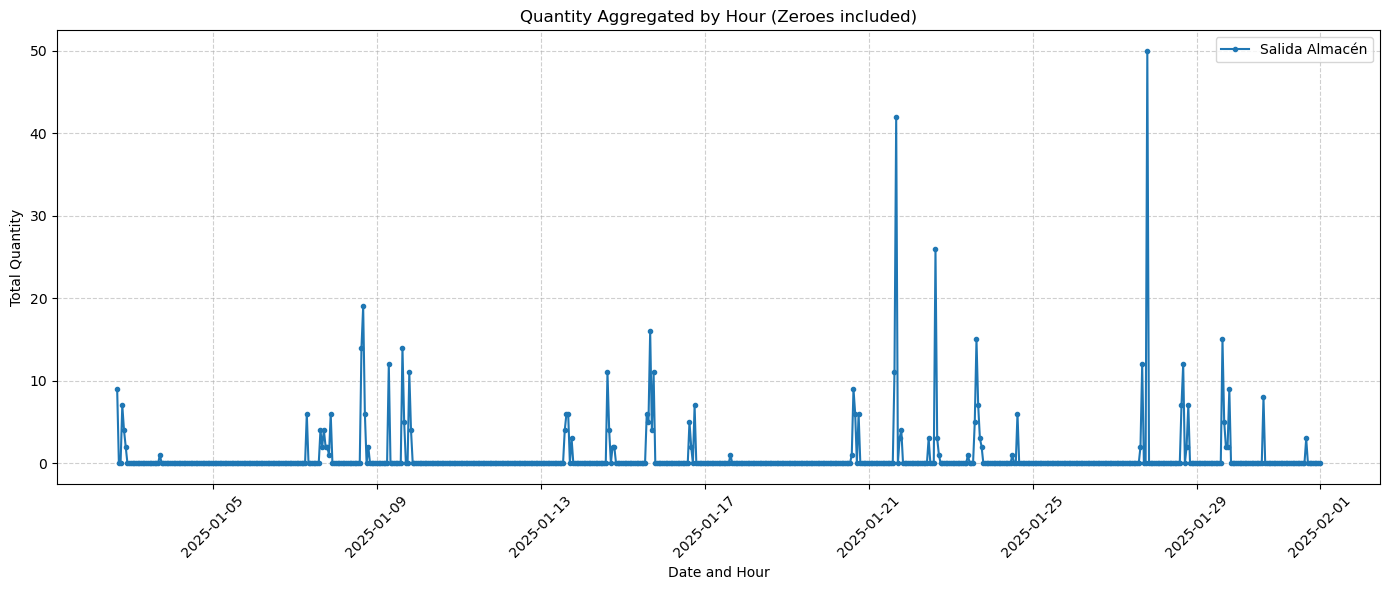

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Preparation ---
# Load your file
df = pd.read_excel('ensaladilla.xls')

# Convert Cantidad to numeric (handling European decimal commas)
if df['Cantidad'].dtype == 'object':
    df['Cantidad'] = df['Cantidad'].str.replace(',', '.').astype(float)

# Convert to datetime
df['Fecha proceso'] = pd.to_datetime(df['Fecha proceso'], dayfirst=False)

# Create a 'Timeline' column truncated to the start of the hour
df['Timeline'] = df['Fecha proceso'].dt.floor('h')

# --- 2. Initial Aggregation ---
df_hour = df.groupby(['Tipo', 'Timeline'], as_index=False)['Cantidad'].sum()

# --- 3. Fill Missing Hours ---
# Define a full range of hours from the first record to the last
full_range = pd.date_range(start=df_hour['Timeline'].min(), 
                           end=df_hour['Timeline'].max(), 
                           freq='h')

# Reindex for each 'Tipo' to include zero-activity hours
df_list = []
for tipo in ['Salida Almacén']:#df_hour['Tipo'].unique():
    subset = df_hour[df_hour['Tipo'] == tipo].set_index('Timeline')
    # This fills the gaps with 0
    subset = subset.reindex(full_range).fillna(0)
    subset['Tipo'] = tipo
    df_list.append(subset.reset_index().rename(columns={'index': 'Timeline'}))

df_final = pd.concat(df_list)
# --- 5. Filter for a specific time window ---
start_date = '2025-01-01'
end_date   = '2025-02-01'

# We use a boolean mask to filter the rows
mask = (df_final['Timeline'] >= start_date) & (df_final['Timeline'] <= end_date)
df_filtered = df_final.loc[mask]

# --- 4. Plotting ---
plt.figure(figsize=(14, 6))

for tipo in df_filtered['Tipo'].unique():
    subset = df_filtered[df_filtered['Tipo'] == tipo]
    # We use drawstyle='steps-post' if you want it to look like a staircase, 
    # or just marker='.' for a standard line plot
    plt.plot(subset['Timeline'], subset['Cantidad'], label=tipo, marker='.')

plt.title('Quantity Aggregated by Hour (Zeroes included)')
plt.xlabel('Date and Hour')
plt.ylabel('Total Quantity')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

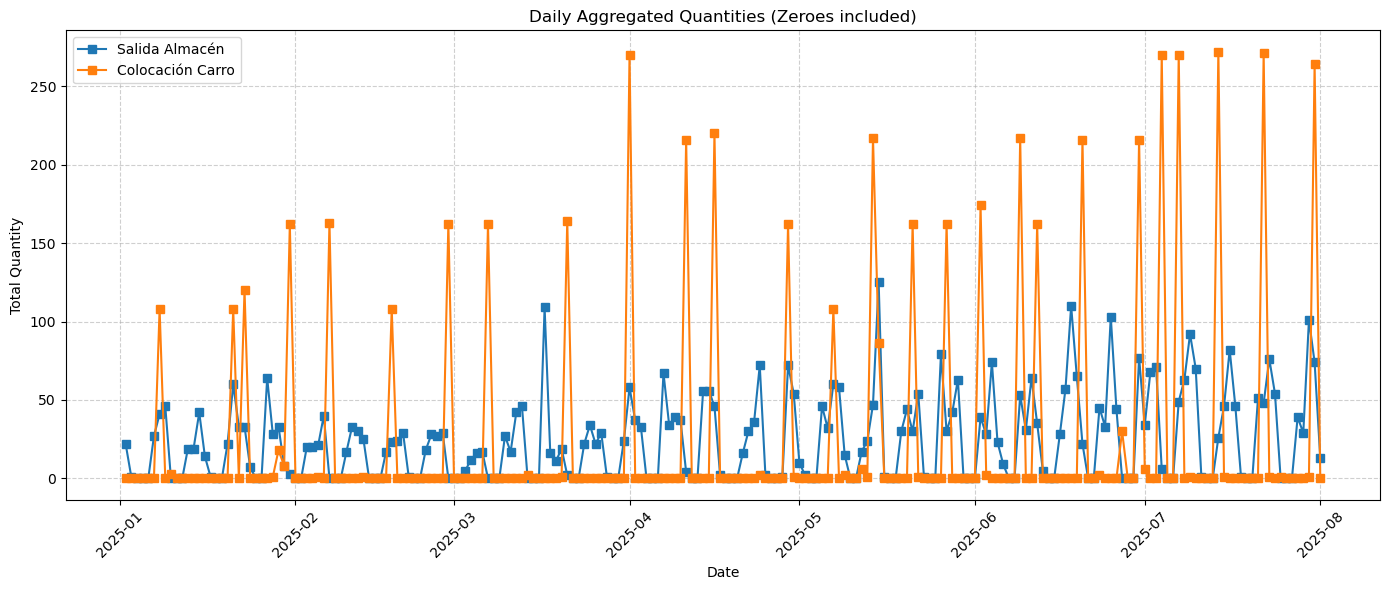

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Preparation & Cleaning ---
df = pd.read_excel('ensaladilla.xls')

if df['Cantidad'].dtype == 'object':
    df['Cantidad'] = df['Cantidad'].str.replace(',', '.').astype(float)

df['Fecha proceso'] = pd.to_datetime(df['Fecha proceso'], dayfirst=False)

# Truncate to the start of the day for daily grouping
df['Timeline_Day'] = df['Fecha proceso'].dt.normalize()

# --- 2. Initial Daily Aggregation ---
df_day_raw = df.groupby(['Tipo', 'Timeline_Day'], as_index=False)['Cantidad'].sum()

# --- 3. Fill Missing Days (The Reindexing Pipeline) ---
# Create a range for every single day
full_day_range = pd.date_range(start=df_day_raw['Timeline_Day'].min(), 
                               end=df_day_raw['Timeline_Day'].max(), 
                               freq='D')

df_list = []
# Filtering specifically for 'Salida Almacén' as per your hourly logic
for tipo in ['Salida Almacén', 'Colocación Carro']:
    subset = df_day_raw[df_day_raw['Tipo'] == tipo].set_index('Timeline_Day')
    # Reindex fills missing dates with 0
    subset = subset.reindex(full_day_range).fillna(0)
    subset['Tipo'] = tipo
    df_list.append(subset.reset_index().rename(columns={'index': 'Timeline_Day'}))

df_final_day = pd.concat(df_list)

# --- 4. Filter for Specific Window ---
start_date = '2025-01-01'
end_date   = '2025-08-01'

mask = (df_final_day['Timeline_Day'] >= start_date) & (df_final_day['Timeline_Day'] <= end_date)
df_filtered_day = df_final_day.loc[mask]

# --- 5. Plotting Daily Data ---
plt.figure(figsize=(14, 6))

for tipo in df_filtered_day['Tipo'].unique():
    subset = df_filtered_day[df_filtered_day['Tipo'] == tipo]
    # For daily plots, a bar chart or a marked line works best
    plt.plot(subset['Timeline_Day'], subset['Cantidad'], label=tipo, marker='s', linestyle='-')

plt.title('Daily Aggregated Quantities (Zeroes included)')
plt.xlabel('Date')
plt.ylabel('Total Quantity')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def process_and_plot_logistics(file_dir, aggregate='day', time_window=None, 
                               info=['Salida Almacén', 'Colocación Carro'], 
                               initial_stock=None):
    """
    General pipeline to aggregate warehouse movements and track stock levels.
    If initial_stock is None, it sets the baseline so the minimum stock is 0.
    """
    # 1. Map frequency
    freq_map = {'hour': 'h', 'day': 'D', 'week': 'W', 'month': 'MS'}
    freq = freq_map.get(aggregate.lower(), 'D')

    # 2. Preparation & Cleaning
    df = pd.read_excel(file_dir)
    
    if df['Cantidad'].dtype == 'object':
        df['Cantidad'] = df['Cantidad'].str.replace(',', '.').astype(float)
    
    df['Fecha proceso'] = pd.to_datetime(df['Fecha proceso'], dayfirst=False)
    
    if freq == 'h':
        df['Timeline'] = df['Fecha proceso'].dt.floor(freq)
    else:
        df['Timeline'] = df['Fecha proceso'].dt.to_period(freq).dt.to_timestamp()

    # 3. Aggregate Raw Data
    df_raw = df.groupby(['Tipo', 'Timeline'], as_index=False)['Cantidad'].sum()

    # 4. Fill Gaps (Reindexing)
    full_range = pd.date_range(start=df_raw['Timeline'].min(), 
                               end=df_raw['Timeline'].max(), 
                               freq=freq)
    
    df_list = []
    for tipo in info:
        subset = df_raw[df_raw['Tipo'] == tipo].set_index('Timeline')
        subset = subset.reindex(full_range).fillna(0)
        subset['Tipo'] = tipo
        df_list.append(subset.reset_index().rename(columns={'index': 'Timeline'}))
    
    df_final = pd.concat(df_list)

    # 5. Pivot for calculation
    df_pivot = df_final.pivot(index='Timeline', columns='Tipo', values='Cantidad').fillna(0)
    
    # Net change calculation
    net_movement = df_pivot.get('Colocación Carro', 0) - df_pivot.get('Salida Almacén', 0)
    cumulative_changes = net_movement.cumsum()

    # --- 6. INITIAL STOCK LOGIC ---
    if initial_stock is None:
        # Find the most negative point in the cumulative sum
        min_point = cumulative_changes.min()
        # If the minimum point is below 0, we need to add that amount as initial stock
        # If it's already above 0, we set initial stock to 0
        initial_stock = abs(min_point) if min_point < 0 else 0
        print(f"Auto-calculated Initial Stock: {initial_stock}")
    
    df_pivot['Stock_Level'] = initial_stock + cumulative_changes

    # 7. Filter for Specific Window
    if time_window:
        start_date, end_date = pd.to_datetime(time_window[0]), pd.to_datetime(time_window[1])
        df_pivot = df_pivot.loc[start_date:end_date]

    # 8. Plotting
    plt.figure(figsize=(14, 7))
    
    # Plotting stock level
    plt.step(df_pivot.index, df_pivot['Stock_Level'], where='post', 
             label=f'Stock (Initial: {initial_stock})', color='black', linewidth=2)
    
    # Visual cues for movement
    if 'Colocación Carro' in df_pivot.columns:
        plt.bar(df_pivot.index, df_pivot['Colocación Carro'], alpha=0.2, color='green', label='Inflow')
    if 'Salida Almacén' in df_pivot.columns:
        plt.bar(df_pivot.index, -df_pivot['Salida Almacén'], alpha=0.2, color='red', label='Outflow')

    plt.title(f'Inventory Levels (Min-Zero Normalized) - By {aggregate.capitalize()}')
    plt.axhline(0, color='red', linestyle='--', alpha=0.3, label='Zero Floor')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return df_pivot

Auto-calculated Initial Stock: 154.0


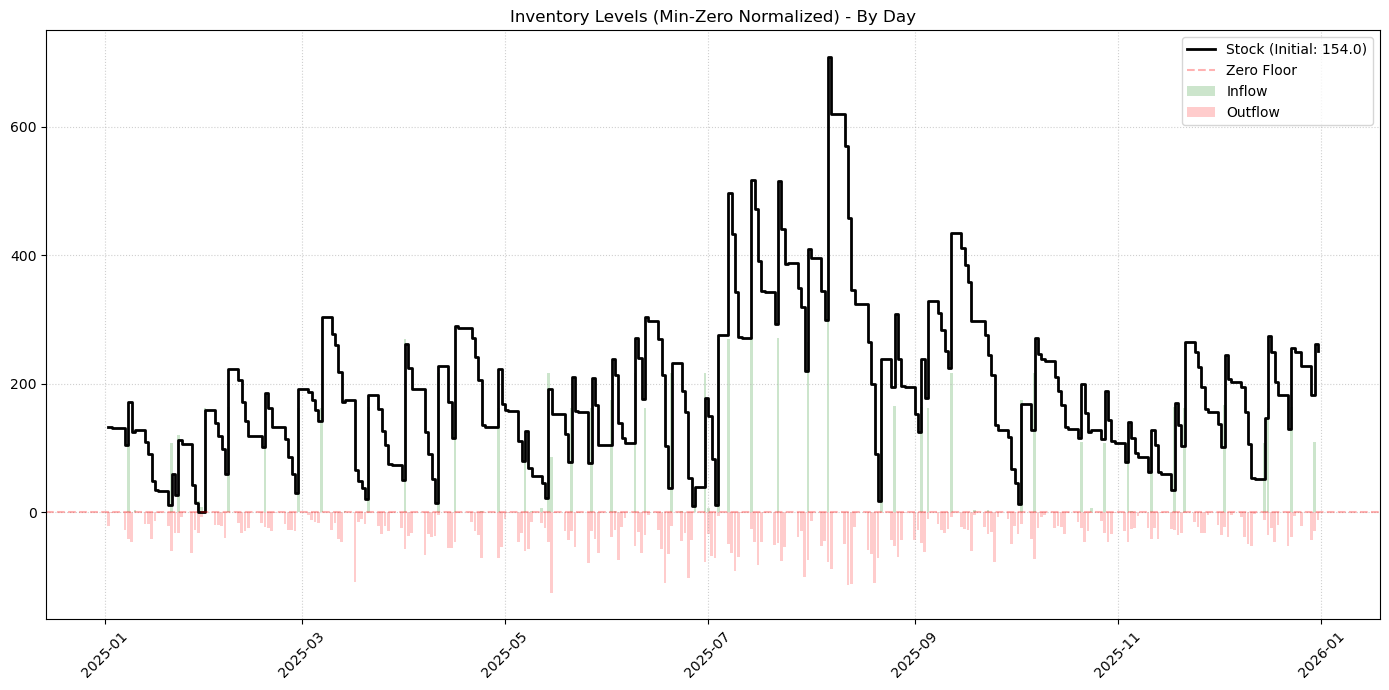

Tipo        Colocación Carro  Salida Almacén  Stock_Level
Timeline                                                 
2025-01-02               0.0            22.0        132.0
2025-01-03               0.0             1.0        131.0
2025-01-04               0.0             0.0        131.0
2025-01-05               0.0             0.0        131.0
2025-01-06               0.0             0.0        131.0


In [7]:
df_pivot = process_and_plot_logistics('ensaladilla.xls', aggregate='day', time_window = None, info=['Salida Almacén', 'Colocación Carro'])
print(df_pivot.head())

In [10]:
df_pivot.columns

Index(['Colocación Carro', 'Salida Almacén', 'Stock_Level'], dtype='object', name='Tipo')

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.offsets import DateOffset

def logistic_forecast_pipeline(file_dir, forecast_days=30, smoothing_window=7, initial_stock=None):
    # --- 1. Load and Preprocess (Same as before) ---
    df = pd.read_csv(file_dir, sep=';')    
    if df['Cantidad'].dtype == 'object':
        df['Cantidad'] = df['Cantidad'].str.replace(',', '.').astype(float)
    df['Fecha proceso'] = pd.to_datetime(df['Fecha proceso'], dayfirst=False)
    df['Timeline'] = df['Fecha proceso'].dt.normalize() # Daily granularity

    # Aggregate to Daily Demand
    df_daily = df.groupby(['Tipo', 'Timeline'], as_index=False)['Cantidad'].sum()
    
    # Create full timeline (including missing days)
    full_range = pd.date_range(start=df_daily['Timeline'].min(), end=df_daily['Timeline'].max(), freq='D')
    
    # Isolate DEMAND (Salida Almacén) for forecasting
    demand_data = df_daily[df_daily['Tipo'] == 'Salida Almacén'].set_index('Timeline')
    demand_data = demand_data.reindex(full_range).fillna(0)
    
    # --- 2. Calculate Stock History (for context) ---
    # We need the other movements too for the stock line
    restock_data = df_daily[df_daily['Tipo'] == 'Colocación Carro'].set_index('Timeline')
    restock_data = restock_data.reindex(full_range).fillna(0)
    
    net_movement = restock_data['Cantidad'] - demand_data['Cantidad']
    cumulative_stock = net_movement.cumsum()
    
    if initial_stock is None:
        min_point = cumulative_stock.min()
        initial_stock = abs(min_point) if min_point < 0 else 0
        
    current_stock_level = initial_stock + cumulative_stock
    current_stock_val = current_stock_level.iloc[-1] # The starting point for our forecast
    last_date = current_stock_level.index[-1]

    # --- 3. The User's Forecast Logic (Applied to Demand) ---
    # Formula: Forecast = (ThisYear_MonthAgo - LastYear_MonthAgo) + LastYear_Now
    
    # We use a rolling mean to smooth out the "sparse" nature of the data
    # Shifted datasets for easy vectorized math:
    daily_demand_smooth = demand_data['Cantidad'].rolling(window=smoothing_window, min_periods=1).mean()
    
    forecast_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=forecast_days, freq='D')
    predicted_demand = []

    for future_date in forecast_dates:
        # A. Get dates for the formula
        date_last_year_now = future_date - DateOffset(years=1)
        
        # "Month Ago" implies we look at the trend relative to the future date's position
        # For simplicity in this loop, we calculate the trend existing at the END of our known data
        # Trend = (Avg Demand last 30 days) - (Avg Demand same 30 days last year)
        
        # Let's calculate the Trend based on the most recent known data (The "Month Ago" part)
        recent_period_end = last_date
        recent_period_start = last_date - DateOffset(days=30)
        
        same_period_last_year_end = recent_period_end - DateOffset(years=1)
        same_period_last_year_start = recent_period_start - DateOffset(years=1)
        
        # Calculate recent volume
        vol_recent = demand_data.loc[recent_period_start:recent_period_end, 'Cantidad'].mean()
        vol_last_year = demand_data.loc[same_period_last_year_start:same_period_last_year_end, 'Cantidad'].mean()
        
        # The Trend Delta
        trend_delta = vol_recent - vol_last_year
        
        # B. Get "Last Year Now" (The base seasonal shape)
        # We handle cases where exact dates usually don't exist (like Feb 29)
        try:
            base_value = demand_data.loc[date_last_year_now, 'Cantidad']
        except KeyError:
            # Fallback for missing dates (use nearest or 0)
            base_value = 0 
            
        # C. Apply Formula
        # We ensure demand doesn't go negative
        prediction = max(0, base_value + trend_delta)
        predicted_demand.append(prediction)

    # --- 4. Convert Demand Forecast to Stock Forecast ---
    # Future Stock = Current Stock - Cumulative Sum of Predicted Demand
    future_demand_series = pd.Series(predicted_demand, index=forecast_dates)
    future_stock_series = current_stock_val - future_demand_series.cumsum()

    # --- 5. Visualization ---
    plt.figure(figsize=(14, 7))
    
    # Plot History (Last 90 days only to keep it readable)
    plot_start = last_date - pd.Timedelta(days=90)
    plt.plot(current_stock_level.loc[plot_start:], label='Historical Stock', color='black', linewidth=2)
    
    # Plot Forecast
    plt.plot(future_stock_series, label='Predicted Stock', color='red', linestyle='--', linewidth=2)
    
    # Add a "Zero Stock" Warning Line
    zero_crossings = future_stock_series[future_stock_series <= 0]
    if not zero_crossings.empty:
        stockout_date = zero_crossings.index[0]
        plt.axvline(stockout_date, color='orange', linestyle=':', linewidth=2)
        plt.text(stockout_date, plt.ylim()[1]*0.5, f' Stockout\n {stockout_date.strftime("%Y-%m-%d")}', color='orange', ha='right')

    plt.title(f'Stock Forecast (Next {forecast_days} Days)')
    plt.xlabel('Date')
    plt.ylabel('Stock Level')
    plt.axhline(0, color='grey', linewidth=0.8)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    return future_stock_series

# usage:
#forecast = logistic_forecast_pipeline('ensaladilla.xls')

In [ ]:
import pandas as pd
from pandas.tseries.offsets import DateOffset

def predict_stockout_for_item(item_df, forecast_days=30):
    """
    The Core Calculator: Processes data for a SINGLE item and returns the predicted stockout date.
    """
    # 1. Timeline Setup
    df_daily = item_df.groupby(['Tipo', 'Timeline'], as_index=False)['Cantidad'].sum()
    
    if df_daily.empty:
        return None, 0 # No data
        
    full_range = pd.date_range(start=df_daily['Timeline'].min(), end=df_daily['Timeline'].max(), freq='D')
    
    # 2. Isolate Demand & Restock
    demand_data = df_daily[df_daily['Tipo'] == 'Salida Almacén'].set_index('Timeline')
    demand_data = demand_data.reindex(full_range).fillna(0)
    
    restock_data = df_daily[df_daily['Tipo'] == 'Colocación Carro'].set_index('Timeline')
    restock_data = restock_data.reindex(full_range).fillna(0)
    
    # 3. Current Stock Calc (Assuming Zero-Floor)
    net_movement = restock_data['Cantidad'] - demand_data['Cantidad']
    cumulative_stock = net_movement.cumsum()
    
    min_point = cumulative_stock.min()
    initial_stock = abs(min_point) if min_point < 0 else 0
        
    current_stock_level = initial_stock + cumulative_stock
    current_stock_val = current_stock_level.iloc[-1]
    last_date = current_stock_level.index[-1]

    # 4. Forecast Logic
    forecast_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=forecast_days, freq='D')
    predicted_demand = []

    # Trend Calc (Extracted from loop for speed)
    recent_start, recent_end = last_date - DateOffset(days=30), last_date
    last_year_start, last_year_end = recent_start - DateOffset(years=1), recent_end - DateOffset(years=1)
    
    vol_recent = demand_data.loc[recent_start:recent_end, 'Cantidad'].mean() if recent_start in demand_data.index else 0
    vol_last_year = demand_data.loc[last_year_start:last_year_end, 'Cantidad'].mean() if last_year_start in demand_data.index else 0
    trend_delta = vol_recent - vol_last_year
    
    # If trend is NaN (missing data), default to 0
    trend_delta = 0 if pd.isna(trend_delta) else trend_delta

    for future_date in forecast_dates:
        date_last_year_now = future_date - DateOffset(years=1)
        base_value = demand_data.loc[date_last_year_now, 'Cantidad'] if date_last_year_now in demand_data.index else 0
        prediction = max(0, base_value + trend_delta)
        predicted_demand.append(prediction)

    # 5. Find Stockout
    future_demand_series = pd.Series(predicted_demand, index=forecast_dates)
    future_stock_series = current_stock_val - future_demand_series.cumsum()
    
    zero_crossings = future_stock_series[future_stock_series <= 0]
    
    stockout_date = zero_crossings.index[0] if not zero_crossings.empty else None
    
    return stockout_date, current_stock_val

def generate_alert_report(file_dir, forecast_days=30):
    """
    The Iteration Loop: Loads the file, loops through items, and generates the dashboard report.
    """
    print("Loading data...")
    df = pd.read_csv(file_dir, sep=';')
    
    # Pre-clean once for speed
    if df['Cantidad'].dtype == 'object':
        df['Cantidad'] = df['Cantidad'].str.replace(',', '.').astype(float)
    df['Fecha proceso'] = pd.to_datetime(df['Fecha proceso'], dayfirst=False)
    df['Timeline'] = df['Fecha proceso'].dt.normalize()

    results = []
    unique_items = df['Referencia'].unique()
    total_items = len(unique_items)
    
    print(f"Analyzing {total_items} items...")
    
    # Group by item and process
    for i, item_id in enumerate(unique_items):
        if i % 500 == 0 and i > 0:
            print(f"Processed {i}/{total_items}...")
            
        item_df = df[df['Referencia'] == item_id]
        stockout_date, current_stock = predict_stockout_for_item(item_df, forecast_days)
        
        results.append({
            'Referencia': item_id,
            'Current_Stock': current_stock,
            'Est_Stockout_Date': stockout_date
        })
        
    # Compile Report
    report_df = pd.DataFrame(results)
    
    # Filter to only show items that ARE going to stock out, and sort by urgency
    urgent_df = report_df.dropna(subset=['Est_Stockout_Date']).sort_values('Est_Stockout_Date')
    
    if urgent_df.empty:
        print("No stockouts predicted in the next 30 days.")
        return urgent_df
    print("\n--- ACTION REQUIRED: STOCKOUT ALERTS ---")
    print(urgent_df.head(15).to_string(index=False))
    
    return urgent_df

# Usage


Loading data...
Analyzing 10 items...
No stockouts predicted in the next 30 days.


# Generate Synthetic Data

In [27]:
from data import generate_synthetic_warehouse_data

df_synthetic = generate_synthetic_warehouse_data(num_items=2500, days=730, output_file='synthetic_inventory.csv')
alert_table = generate_alert_report('synthetic_inventory.csv', forecast_days=30)


Generating synthetic data for 2500 items over 730 days...
Saving 456250 rows to synthetic_inventory.csv...
Done!
Loading data...
Analyzing 2500 items...
Processed 500/2500...
Processed 1000/2500...
Processed 1500/2500...
Processed 2000/2500...
No stockouts predicted in the next 30 days.


In [9]:
df_synthetic.columns

Index(['Referencia', 'Descripción', 'Tipo', 'Cantidad', 'Fecha proceso'], dtype='object')